# Question 8 — Quelle politique par type de séjour, et qui remplit la semaine ?

**Auteur : Wenceslas Bouity** — Projet Valmont, Datamining B3 (ECE Paris), sujet 9.

La question 7 a montré que Valmont a **quatre types de séjours** et non les trois segments déclarés. Cette
question en tire les conséquences commerciales : pour chaque type, qu'est-ce qu'il rapporte, qu'est-ce qu'il
coûte en annulations, quand remplit-il l'hôtel, et quelle condition de vente faut-il lui appliquer ?

Elle répond aussi à une question précise de la direction : **qui remplit les nuits de semaine ?**

**Méthode** : profil chiffré de chaque type (prix, annulation, services, part en semaine), décomposition du
revenu perdu, puis une décision par type avec son gain estimé et sa plage de sensibilité.

**Point de départ** : `data/clean/valmont_clean.csv` et `data/clean/q7_types_sejours.csv`, le fichier de types
produit par la question 7.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import chi2_contingency

pd.set_option("display.width", 210)
pd.set_option("display.max_columns", 40)

# Memes couleurs qu'en Q7, attachees au type et non a son rang :
# un type garde sa couleur d'un graphique a l'autre et d'un notebook a l'autre.
COULEUR_TYPE = {
    "Court séjour de dernière minute": "#00b894",
    "Long séjour individuel": "#f2a600",
    "Groupe et séminaire": "#257de0",
    "Réservation très anticipée": "#ec4647",
}
# Ordre de lecture : du type le plus sur au plus risque (taux d'annulation croissant, Q7).
ORDRE = list(COULEUR_TYPE)
# Etiquettes courtes, pour les axes des graphiques seulement.
COURT = {"Court séjour de dernière minute": "Court séjour\ndernière minute",
         "Long séjour individuel": "Long séjour\nindividuel",
         "Groupe et séminaire": "Groupe et\nséminaire",
         "Réservation très anticipée": "Réservation\ntrès anticipée"}
ENCRE, ENCRE_2, GRILLE = "#191919", "#666666", "#dcdcdc"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRILLE, "axes.labelcolor": ENCRE, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlecolor": ENCRE, "axes.grid": True,
    "grid.color": GRILLE, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": ENCRE_2, "ytick.color": ENCRE_2, "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

reservations = pd.read_csv("../data/clean/valmont_clean.csv")
types_q7 = pd.read_csv("../data/clean/q7_types_sejours.csv")

# Jointure interne : les 6 anomalies de la Q9 n'ont pas de type et sortent ici,
# exactement comme elles etaient sorties de la classification en Q7.
sejours = reservations.merge(types_q7, on="reservation_id", how="inner")

print("Réservations du fichier propre :", len(reservations))
print("Réservations typées en Q7      :", len(types_q7))
print("Après jointure                 :", len(sejours))
print("Perdues dans la jointure       :", len(types_q7) - len(sejours))
print("\nEffectif par type :")
print(sejours["type_sejour"].value_counts().reindex(ORDRE).to_string())

Réservations du fichier propre : 800
Réservations typées en Q7      : 794
Après jointure                 : 794
Perdues dans la jointure       : 0

Effectif par type :
type_sejour
Court séjour de dernière minute    363
Long séjour individuel             171
Groupe et séminaire                134
Réservation très anticipée         126


## 1. Contrôle de la jointure

La jointure est faite sur `reservation_id`, identifiant unique vérifié en question 7. Les 6 réservations
marquées comme anomalies n'ont pas de type : elles sont écartées ici comme elles l'étaient de la
classification, et restent traitées en question 9. Aucune ligne n'est perdue autrement, et les effectifs par
type sont identiques à ceux de la question 7 — c'est ce que contrôle la cellule ci-dessus.

In [2]:
# Deux grandeurs de revenu servent dans tout le notebook, definies une fois ici.
# revenu_potentiel : ce que la reservation aurait rapporte en chambre si elle avait ete honoree.
# Le prix est un prix par nuit et par chambre (verifie dans le notebook 00), d'ou le produit.
sejours["revenu_potentiel"] = sejours["prix_nuit_eur"] * sejours["nb_nuits"]
sejours["revenu_realise"] = sejours["revenu_potentiel"] * (1 - sejours["a_annule"])
sejours["revenu_perdu"] = sejours["revenu_potentiel"] * sejours["a_annule"]
sejours["petit_dejeuner_oui"] = (sejours["petit_dejeuner"] == "oui").astype(int)
sejours["en_semaine"] = 1 - sejours["weekend"]

print("Sur les", len(sejours), "réservations analysées :")
print(f"  revenu potentiel : {sejours['revenu_potentiel'].sum():>10,.0f} €")
print(f"  revenu réalisé   : {sejours['revenu_realise'].sum():>10,.0f} €")
print(f"  revenu annulé    : {sejours['revenu_perdu'].sum():>10,.0f} €  "
      f"({sejours['revenu_perdu'].sum() / sejours['revenu_potentiel'].sum():.1%} du potentiel)")
print(f"\n  nuitées vendues  : {sejours.loc[sejours['a_annule'] == 0, 'nb_nuits'].sum():>6,.0f}")
print(f"  nuitées annulées : {sejours.loc[sejours['a_annule'] == 1, 'nb_nuits'].sum():>6,.0f}")

Sur les 794 réservations analysées :
  revenu potentiel :    454,228 €
  revenu réalisé   :    338,948 €
  revenu annulé    :    115,279 €  (25.4% du potentiel)

  nuitées vendues  :  1,720
  nuitées annulées :    620


## 2. La fiche chiffrée des quatre types

C'est le tableau de référence de la question : tout ce qu'un directeur commercial doit savoir sur un type pour
décider de ses conditions de vente.

In [3]:
fiche = sejours.groupby("type_sejour").agg(
    reservations=("type_sejour", "size"),
    personnes=("nb_personnes", "mean"),
    nuits=("nb_nuits", "mean"),
    delai_median=("delai_reservation_j", "median"),
    prix_nuit=("prix_nuit_eur", "mean"),
    panier=("revenu_potentiel", "mean"),
    taux_annulation=("a_annule", "mean"),
    part_en_semaine=("en_semaine", "mean"),
    petit_dejeuner=("petit_dejeuner_oui", "mean"),
).reindex(ORDRE)

fiche["part_reservations"] = fiche["reservations"] / len(sejours)
fiche["revenu_realise"] = sejours.groupby("type_sejour")["revenu_realise"].sum().reindex(ORDRE)
fiche["revenu_perdu"] = sejours.groupby("type_sejour")["revenu_perdu"].sum().reindex(ORDRE)
fiche["part_revenu_realise"] = fiche["revenu_realise"] / fiche["revenu_realise"].sum()
fiche["part_revenu_perdu"] = fiche["revenu_perdu"] / fiche["revenu_perdu"].sum()
fiche["perdu_par_reservation"] = fiche["revenu_perdu"] / fiche["reservations"]

colonnes_profil = ["reservations", "part_reservations", "personnes", "nuits", "delai_median",
                   "prix_nuit", "panier", "taux_annulation", "part_en_semaine", "petit_dejeuner"]
print("Profil des quatre types :")
print(fiche[colonnes_profil].round(3).to_string())

Profil des quatre types :
                                 reservations  part_reservations  personnes  nuits  delai_median  prix_nuit   panier  taux_annulation  part_en_semaine  petit_dejeuner
type_sejour                                                                                                                                                           
Court séjour de dernière minute           363              0.457      1.350  2.116          13.0    198.715  414.676            0.187            0.680           0.466
Long séjour individuel                    171              0.215      1.789  4.912          25.0    199.244  965.371            0.228            0.678           0.386
Groupe et séminaire                       134              0.169     11.537  2.328          54.5    185.127  441.318            0.336            0.769           0.485
Réservation très anticipée                126              0.159      2.706  3.333          96.0    192.412  630.836            0.437      

In [4]:
def intervalle_wilson(succes, effectif, z=1.96):
    """Intervalle de confiance a 95 % d'une proportion, methode de Wilson.

    Preferee a la formule normale classique : elle reste valide sur de petits
    effectifs (ici 126 reservations pour le plus petit type) et ne sort jamais de [0, 1].
    """
    p = succes / effectif
    denominateur = 1 + z ** 2 / effectif
    centre = (p + z ** 2 / (2 * effectif)) / denominateur
    demi_largeur = z * np.sqrt(p * (1 - p) / effectif + z ** 2 / (4 * effectif ** 2)) / denominateur
    return centre - demi_largeur, centre + demi_largeur

print("Taux d'annulation et intervalle de confiance à 95 % :")
bornes = {}
for type_sejour in ORDRE:
    bloc = sejours[sejours["type_sejour"] == type_sejour]
    bas, haut = intervalle_wilson(bloc["a_annule"].sum(), len(bloc))
    bornes[type_sejour] = (bas, haut)
    print(f"  {type_sejour:33s} n = {len(bloc):3d}   {bloc['a_annule'].mean():.1%}   "
          f"IC95 [{bas:.1%} ; {haut:.1%}]")

print("\nLes intervalles du type le plus sûr et du type le plus risqué se recouvrent-ils ?",
      "non" if bornes[ORDRE[0]][1] < bornes[ORDRE[3]][0] else "oui")

Taux d'annulation et intervalle de confiance à 95 % :
  Court séjour de dernière minute   n = 363   18.7%   IC95 [15.1% ; 23.1%]
  Long séjour individuel            n = 171   22.8%   IC95 [17.2% ; 29.7%]
  Groupe et séminaire               n = 134   33.6%   IC95 [26.1% ; 41.9%]
  Réservation très anticipée        n = 126   43.7%   IC95 [35.3% ; 52.4%]

Les intervalles du type le plus sûr et du type le plus risqué se recouvrent-ils ? non


**Lecture.** Les quatre types ne sont pas quatre nuances d'un même comportement, ils demandent des
conditions différentes :

- **Court séjour de dernière minute** — 46 % des réservations, le type le plus sûr (18,7 % d'annulation), un
  panier de 415 €. C'est le socle du volume.
- **Long séjour individuel** — 22 % des réservations mais un panier de **965 €**, deux fois et demie celui du
  court séjour, pour un risque à peine plus élevé (22,8 %). C'est le type le plus rentable de Valmont.
- **Groupe et séminaire** — 17 % des réservations, 33,6 % d'annulation, et **77 % de ses nuits en semaine**,
  la proportion la plus forte des quatre.
- **Réservation très anticipée** — 16 % des réservations et 43,7 % d'annulation : plus de deux réservations
  sur cinq ne viennent jamais.

Les intervalles de confiance du type le plus sûr (15,1 % – 23,1 %) et du plus risqué (35,3 % – 52,4 %) ne se
recouvrent pas : l'écart n'est pas un effet d'échantillonnage. En revanche ceux du court et du long séjour
individuels se recouvrent largement — **ces deux types ne se distinguent pas par le risque, mais par le
panier**, et c'est exactement ce qui justifie qu'ils reçoivent des politiques différentes : l'un se pilote en
volume, l'autre en valeur.

## 3. Où part le revenu annulé ?

Comparer des taux d'annulation ne suffit pas pour décider : un type peut annuler beaucoup sans coûter cher s'il
réserve peu et bon marché. Je rapporte donc chaque type à ce qu'il pèse réellement en euros.

In [5]:
print("Revenu par type, en euros et en part du total :")
print(fiche[["part_reservations", "revenu_realise", "part_revenu_realise",
             "revenu_perdu", "part_revenu_perdu", "perdu_par_reservation"]].round(3).to_string())

print(f"\nRevenu annulé total : {fiche['revenu_perdu'].sum():,.0f} € "
      f"sur {sejours['revenu_potentiel'].sum():,.0f} € de potentiel")

Revenu par type, en euros et en part du total :
                                 part_reservations  revenu_realise  part_revenu_realise  revenu_perdu  part_revenu_perdu  perdu_par_reservation
type_sejour                                                                                                                                    
Court séjour de dernière minute              0.457       120571.93                0.356      29955.36              0.260                 82.522
Long séjour individuel                       0.215       132578.49                0.391      32499.97              0.282                190.058
Groupe et séminaire                          0.169        41022.30                0.121      18114.31              0.157                135.181
Réservation très anticipée                   0.159        44775.64                0.132      34709.71              0.301                275.474

Revenu annulé total : 115,279 € sur 454,228 € de potentiel


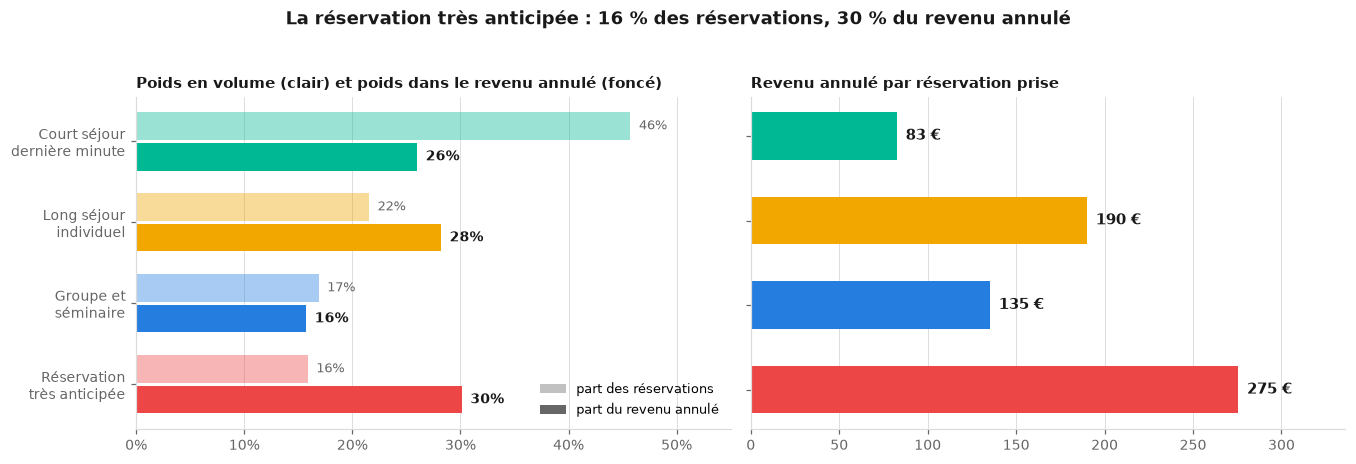

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.0))
y = np.arange(len(ORDRE))
couleurs = [COULEUR_TYPE[t] for t in ORDRE]

# Panneau 1 : deux parts, donc deux barres sur la MEME echelle en pourcentage.
ax = axes[0]
ax.barh(y - 0.19, fiche["part_reservations"], height=0.34, color=couleurs, alpha=0.40)
ax.barh(y + 0.19, fiche["part_revenu_perdu"], height=0.34, color=couleurs)
for i, (a, b) in enumerate(zip(fiche["part_reservations"], fiche["part_revenu_perdu"])):
    ax.text(a + 0.008, i - 0.19, f"{a:.0%}", va="center", fontsize=8.5, color=ENCRE_2)
    ax.text(b + 0.008, i + 0.19, f"{b:.0%}", va="center", fontsize=9, color=ENCRE, fontweight="bold")
ax.set_yticks(y, [COURT[t] for t in ORDRE])
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlim(0, 0.55)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Poids en volume (clair) et poids dans le revenu annulé (foncé)", loc="left", fontsize=10)
# Legende neutre : la couleur porte le type, la teinte porte la mesure.
legende = [Patch(facecolor=ENCRE_2, alpha=0.40, label="part des réservations"),
           Patch(facecolor=ENCRE_2, label="part du revenu annulé")]
ax.legend(handles=legende, loc="lower right", fontsize=8.5)

# Panneau 2 : une seule mesure, en euros.
ax = axes[1]
ax.barh(y, fiche["perdu_par_reservation"], height=0.56, color=couleurs)
for i, v in enumerate(fiche["perdu_par_reservation"]):
    ax.text(v + 5, i, f"{v:,.0f} €", va="center", fontweight="bold", color=ENCRE, fontsize=9.5)
ax.set_yticks(y, ["" for _ in ORDRE])
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlim(0, fiche["perdu_par_reservation"].max() * 1.22)
ax.set_title("Revenu annulé par réservation prise", loc="left", fontsize=10)

fig.suptitle("La réservation très anticipée : 16 % des réservations, 30 % du revenu annulé",
             fontsize=12, fontweight="bold", color=ENCRE, y=1.04)
fig.tight_layout()
plt.show()

**Lecture — c'est le résultat qui commande la décision.**

- La **réservation très anticipée** pèse 16 % des réservations mais **30 % du revenu annulé**. Chaque
  réservation de ce type laisse en moyenne **275 € de revenu annulé**, contre 83 € pour un court séjour :
  trois fois et demie plus.
- Le **long séjour individuel** est le premier contributeur au revenu réalisé (39 %) et, mécaniquement, le
  premier au revenu annulé en euros (28 %) alors que son taux d'annulation est faible — parce que son panier
  est le plus élevé. Il ne faut donc pas le durcir, il faut le protéger.
- Les **groupes** coûtent 135 € par réservation malgré un taux de 33,6 %, parce que leurs séjours sont courts.

Sur l'ensemble, **25,4 % du revenu chambre potentiel part en annulation** (115 279 € sur 454 228 €). C'est
l'ordre de grandeur de ce que la nouvelle politique cherche à récupérer.

## 4. Qui remplit la semaine ?

La direction pose la question parce que les nuits de semaine sont les plus difficiles à vendre. Deux façons de
répondre, qui ne disent pas la même chose :

1. **Quelle part de chaque type tombe en semaine ?** — répond à « ce type est-il un client de semaine ? »
2. **Quelle part des nuitées de semaine chaque type fournit-il ?** — répond à « sur qui compter pour remplir
   un mardi ? »

La première est une proportion dans le type, la seconde une part de marché. Un type peut être très « semaine »
et ne rien peser.

In [7]:
nuitees_semaine = sejours[sejours["weekend"] == 0].groupby("type_sejour")["nb_nuits"].sum().reindex(ORDRE)
nuitees_weekend = sejours[sejours["weekend"] == 1].groupby("type_sejour")["nb_nuits"].sum().reindex(ORDRE)

semaine = pd.DataFrame({
    "part_du_type_en_semaine": fiche["part_en_semaine"],
    "nuitees_semaine": nuitees_semaine,
    "part_des_nuitees_semaine": nuitees_semaine / nuitees_semaine.sum(),
    "part_des_nuitees_weekend": nuitees_weekend / nuitees_weekend.sum(),
})
print("Semaine et week-end par type :")
print(semaine.round(3).to_string())
print(f"\nNuitées de semaine : {nuitees_semaine.sum():,.0f}  |  de week-end : {nuitees_weekend.sum():,.0f}"
      f"   ({nuitees_semaine.sum() / (nuitees_semaine.sum() + nuitees_weekend.sum()):.0%} en semaine)")

Semaine et week-end par type :
                                 part_du_type_en_semaine  nuitees_semaine  part_des_nuitees_semaine  part_des_nuitees_weekend
type_sejour                                                                                                                  
Court séjour de dernière minute                    0.680              531                     0.328                     0.328
Long séjour individuel                             0.678              573                     0.354                     0.369
Groupe et séminaire                                0.769              233                     0.144                     0.109
Réservation très anticipée                         0.627              280                     0.173                     0.194

Nuitées de semaine : 1,617  |  de week-end : 723   (69% en semaine)


In [8]:
# Le lien type x semaine est-il reel, ou un effet du hasard ?
table = pd.crosstab(sejours["type_sejour"], sejours["weekend"])
chi2, p, _, _ = chi2_contingency(table)
print(f"Khi-deux sur les 4 types ensemble : chi² = {chi2:.2f}, p = {p:.4f}")

# Comparaison du type le plus "semaine" et du moins "semaine", pris isolement
paire = table.loc[["Groupe et séminaire", "Réservation très anticipée"]]
chi2_p, p_p, _, _ = chi2_contingency(paire)
print(f"Groupe et séminaire (76,9 %) contre Réservation très anticipée (62,7 %) : "
      f"chi² = {chi2_p:.2f}, p = {p_p:.4f}")
print("\nAvec 4 types, six comparaisons deux à deux sont possibles ; le seuil de Bonferroni")
print(f"serait 0,05 / 6 = {0.05/6:.4f}. La comparaison ci-dessus ne le franchit pas.")

Khi-deux sur les 4 types ensemble : chi² = 6.39, p = 0.0941
Groupe et séminaire (76,9 %) contre Réservation très anticipée (62,7 %) : chi² = 5.55, p = 0.0185

Avec 4 types, six comparaisons deux à deux sont possibles ; le seuil de Bonferroni
serait 0,05 / 6 = 0.0083. La comparaison ci-dessus ne le franchit pas.


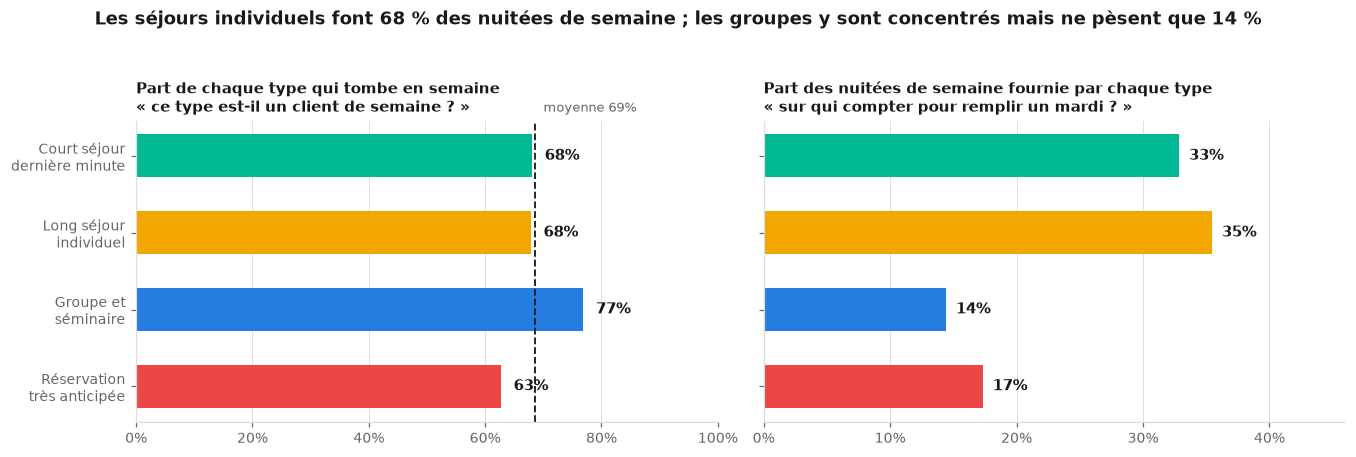

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12.4, 3.9))
y = np.arange(len(ORDRE))
couleurs = [COULEUR_TYPE[t] for t in ORDRE]

ax = axes[0]
ax.barh(y, semaine["part_du_type_en_semaine"], height=0.56, color=couleurs)
ax.axvline(1 - sejours["weekend"].mean(), color=ENCRE, linewidth=1.2, linestyle="--")
ax.text(1 - sejours["weekend"].mean(), 1.02, f"  moyenne {1 - sejours['weekend'].mean():.0%}",
        transform=ax.get_xaxis_transform(), va="bottom", color=ENCRE_2, fontsize=8.5)
for i, v in enumerate(semaine["part_du_type_en_semaine"]):
    ax.text(v + 0.022, i, f"{v:.0%}", va="center", fontweight="bold", color=ENCRE, fontsize=9.5)
ax.set_yticks(y, [COURT[t] for t in ORDRE]); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlim(0, 1.0); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Part de chaque type qui tombe en semaine\n« ce type est-il un client de semaine ? »",
             loc="left", fontsize=10)

ax = axes[1]
ax.barh(y, semaine["part_des_nuitees_semaine"], height=0.56, color=couleurs)
for i, v in enumerate(semaine["part_des_nuitees_semaine"]):
    ax.text(v + 0.008, i, f"{v:.0%}", va="center", fontweight="bold", color=ENCRE, fontsize=9.5)
ax.set_yticks(y, ["" for _ in ORDRE]); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlim(0, 0.46); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Part des nuitées de semaine fournie par chaque type\n« sur qui compter pour remplir un mardi ? »",
             loc="left", fontsize=10)

fig.suptitle("Les séjours individuels font 68 % des nuitées de semaine ; les groupes y sont concentrés mais ne pèsent que 14 %",
             fontsize=11.5, fontweight="bold", color=ENCRE, y=1.05)
fig.tight_layout()
plt.show()

**Lecture — la réponse n'est pas celle qu'on attend.**

Les quatre types tombent en semaine dans des proportions proches (62,7 % à 76,9 %) et le test d'ensemble
**n'est pas significatif** (khi-deux, p = 0,094). Pris isolément, l'écart entre les groupes (76,9 %) et les
réservations très anticipées (62,7 %) l'est (p = 0,019), mais six comparaisons deux à deux sont possibles et
ce résultat ne passe pas le seuil de Bonferroni (0,0083). **Je ne conclus donc pas qu'un type remplit la
semaine plus qu'un autre.**

Ce qui est en revanche solide, c'est la part de marché : **les deux types individuels fournissent 68 % des
1 617 nuitées de semaine** (35 % pour le long séjour, 33 % pour le court séjour). Les groupes, malgré leur
concentration en semaine, n'en fournissent que 14 % — ils sont peu nombreux et leurs séjours sont courts.

**Conséquence pour la décision** : le levier de remplissage de la semaine n'est pas de changer le mix de
clientèle, c'est d'augmenter le volume individuel en semaine. Les groupes restent une cible, mais comme
complément à forte valeur sur les creux, pas comme solution de volume.

## 5. Les services : y a-t-il un levier ?

La commande mentionne les services. Je regarde le seul service présent dans les données, le petit-déjeuner,
et la capacité séminaire des hôtels effectivement réservés par chaque type.

In [10]:
services = sejours.groupby("type_sejour").agg(
    petit_dejeuner=("petit_dejeuner_oui", "mean"),
    salles_seminaire=("salles_seminaire", "mean"),
    categorie_5e=("categorie", lambda s: (s == "5 étoiles").mean()),
    fidelite=("nuitees_cumulees_client", "mean"),
).reindex(ORDRE)
services["nuitees_sans_pdej"] = (sejours[sejours["petit_dejeuner_oui"] == 0]
                                 .groupby("type_sejour")["nb_nuits"].sum().reindex(ORDRE))
print("Services et contexte hôtelier par type :")
print(services.round(3).to_string())

chi2, p, _, _ = chi2_contingency(pd.crosstab(sejours["type_sejour"], sejours["petit_dejeuner_oui"]))
print(f"\nKhi-deux type × petit-déjeuner : chi² = {chi2:.2f}, p = {p:.3f}")

prix_moyen = sejours["prix_nuit_eur"].mean()
print(f"\nNuitées vendues sans petit-déjeuner, par type (gisement de montée en gamme) :")
print(services["nuitees_sans_pdej"].astype(int).to_string())

Services et contexte hôtelier par type :
                                 petit_dejeuner  salles_seminaire  categorie_5e  fidelite  nuitees_sans_pdej
type_sejour                                                                                                 
Court séjour de dernière minute           0.466             4.504         0.256    11.482                414
Long séjour individuel                    0.386             4.678         0.281    10.906                509
Groupe et séminaire                       0.485             5.104         0.299     9.694                158
Réservation très anticipée                0.405             4.000         0.333    11.238                248

Khi-deux type × petit-déjeuner : chi² = 4.71, p = 0.194

Nuitées vendues sans petit-déjeuner, par type (gisement de montée en gamme) :
type_sejour
Court séjour de dernière minute    414
Long séjour individuel             509
Groupe et séminaire                158
Réservation très anticipée         248


**Lecture.** La prise de petit-déjeuner va de 38,6 % (long séjour individuel) à 48,5 % (groupe et
séminaire), mais l'écart n'est pas significatif (p = 0,19). Les quatre types réservent par ailleurs des hôtels
très comparables : même capacité séminaire moyenne, même part de 5 étoiles.

**Il n'y a donc pas de politique de services à bâtir type par type sur la base d'un écart de comportement.**
Le levier existe, mais il est de volume : le long séjour individuel est à la fois le type le plus rentable et
celui qui prend le moins de petit-déjeuner, alors que ses séjours sont les plus longs. C'est le gisement le
plus clair — et c'est aussi une limite du jeu de données, qui ne contient ni le prix du petit-déjeuner ni les
autres services vendus sur place.